# Inestabilidad de Rayleigh - Taylor

## Objetivo
En este proyecto analizaremos el comportamiento de la ecuacion de inestabilidad de Rayleigh - Taylor con uno de los ejemplos incluidos en el codigo de magnetohidrodinamica del software libre PLUTO, adicionalmente se intentara replicar el comportamiento de estas ecuaciones en un codigo propio construido en python

## Marco Teórico: Inestabilidad de Rayleigh-Taylor en Magnetohidrodinámica (MHD)

Este proyecto modela la inestabilidad de Rayleigh-Taylor (RT) para fluidos incompresibles en el régimen de MHD ideal (conductividad eléctrica infinita y sin viscosidad). 

### 1. Ecuaciones Gobernantes
La dinámica del sistema está dictada por las leyes de conservación de masa, momento y flujo magnético:

* **Ecuación de Continuidad (Incompresibilidad):**
  $$ \nabla \cdot \mathbf{v} = 0 $$
  $$ \frac{\partial \rho}{\partial t} + (\mathbf{v} \cdot \nabla)\rho = 0 $$

* **Ecuación de Momento (Navier-Stokes con fuerza de Lorentz):**
  $$ \rho \left( \frac{\partial \mathbf{v}}{\partial t} + (\mathbf{v} \cdot \nabla)\mathbf{v} \right) = -\nabla p + \rho \mathbf{g} + \frac{1}{\mu_0} (\nabla \times \mathbf{B}) \times \mathbf{B} $$

* **Ecuación de Inducción Ideal:**
  $$ \frac{\partial \mathbf{B}}{\partial t} = \nabla \times (\mathbf{v} \times \mathbf{B}) $$

* **Condición Solenoidal:**
  $$ \nabla \cdot \mathbf{B} = 0 $$

### 2. Configuración del Estado Base
Consideramos un sistema de dos fluidos separados por una interfaz plana en $z = 0$, sometidos a una gravedad uniforme $\mathbf{g} = -g \hat{z}$ y un campo magnético horizontal constante $\mathbf{B}_0 = B_0 \hat{x}$.

* **Región Superior ($z > 0$):** Fluido pesado con densidad $\rho_1$.
* **Región Inferior ($z < 0$):** Fluido ligero con densidad $\rho_2$ (donde $\rho_1 > \rho_2$).

En equilibrio estático ($\mathbf{v}_0 = 0$), el balance hidrostático es:
$$ \frac{d}{dz} \left( p_0 + \frac{B_0^2}{2\mu_0} \right) = -\rho_0 g $$

### 3. Relación de Dispersión
Aplicando teoría de perturbaciones lineales, donde las variables adoptan la forma de modos normales $f_1(x,y,z,t) = \hat{f}_1(z) e^{\gamma t + i(k_x x + k_y y)}$, y resolviendo las condiciones de contorno en la interfaz, se obtiene la relación de dispersión para la inestabilidad:

$$ \gamma^2 = g k \left( \frac{\rho_1 - \rho_2}{\rho_1 + \rho_2} \right) - \frac{2(\mathbf{k} \cdot \mathbf{B}_0)^2}{\mu_0 (\rho_1 + \rho_2)} $$

Donde:
* $\gamma$: Tasa de crecimiento de la inestabilidad.
* $\mathbf{k}$: Vector de onda de la perturbación horizontal ($k = |\mathbf{k}|$).

### 4. Análisis Físico de la Inestabilidad
La ecuación de dispersión revela dos mecanismos opuestos:

1. **Término Gravitatorio (Desestabilizador):** El término proporcional a $gk$ contiene el número de Atwood. Al ser $\rho_1 > \rho_2$, este término es positivo e impulsa el crecimiento de la inestabilidad.
2. **Término Magnético (Estabilizador):** El término proporcional a $(\mathbf{k} \cdot \mathbf{B}_0)^2$ es negativo. Representa la **tensión magnética** que actúa como una fuerza restauradora cuando la perturbación dobla las líneas de campo.

**Condición de Estabilidad:** 
Las perturbaciones con longitudes de onda muy cortas (alto $k$) son suprimidas por completo por el campo magnético. El sistema es estable ($\gamma^2 < 0$) para números de onda que superan el valor crítico:
$$ k_c = \frac{g \mu_0 (\rho_1 - \rho_2)}{2 B_0^2 \cos^2\theta} $$
*(Donde $\theta$ es el ángulo entre el vector de onda $\mathbf{k}$ y el campo magnético $\mathbf{B}_0$).*

## 5. Condiciones de Frontera y de Interfaz

Para resolver el sistema diferencial linealizado y obtener la relación de dispersión, se deben aplicar condiciones en los límites del dominio y en la superficie de separación de los fluidos.

### Condiciones de Contorno Espaciales (Límites del Dominio)
* **Direcciones Horizontales ($x, y$):** Se asumen **condiciones periódicas**. Esto permite modelar el crecimiento de las ondas de inestabilidad de forma continua sin que interfieran efectos de pared.
  $$ f(x, y, z, t) = f(x + L_x, y + L_y, z, t) $$
* **Dirección Vertical ($z$):**
  * **Modelo Analítico (Dominio Infinito):** Las amplitudes de las perturbaciones físicas no pueden crecer infinitamente. Por lo tanto, deben decaer a cero lejos de la interfaz:
    $$ \hat{v}_z \to 0 \quad \text{cuando} \quad z \to \pm \infty $$
  * **Modelo Computacional (Dominio Finito):** En simuladores (como PLUTO), se suelen emplear **condiciones de pared reflectante** (slip boundaries) en los bordes superior e inferior, obligando a que la velocidad normal se anule:
    $$ v_z = 0 \quad \text{en} \quad z = z_{min}, z_{max} $$

### Condiciones de Salto en la Interfaz ($z = 0$)
Las soluciones del fluido pesado y ligero deben conectarse físicamente en la interfaz mediante dos condiciones de salto (donde el corchete $[f]$ denota la diferencia del valor a través de $z=0$):

1. **Condición Cinemática:** La interfaz debe mantenerse unida sin separarse. Esto exige que la componente vertical de la velocidad (normal a la interfaz estática) sea continua:
   $$ [\hat{v}_z] = 0 \implies \hat{v}_{z1} (z=0^+) = \hat{v}_{z2} (z=0^-) $$
2. **Condición Dinámica:** La presión total (térmica más magnética) debe equilibrar la deformación de la superficie producida por la fuerza gravitatoria. La continuidad del esfuerzo normal requiere:
   $$ \left[ \Pi_1 \right] = \left[ p_1 + \frac{\mathbf{B}_0 \cdot \mathbf{B}_1}{\mu_0} \right] \quad \text{es continua a través del límite deformado.} $$

### Avances Recientes en el Modelado de la Inestabilidad de Rayleigh-Taylor (RTI)

El estudio de la inestabilidad de Rayleigh-Taylor (RTI) en plasmas astrofísicos, como las prominencias solares, ha evolucionado al superar las limitaciones de las aproximaciones lineales clásicas. Actualmente, la investigación se centra en la dinámica no lineal y los efectos del campo magnético sobre el plasma. Los procesos y avances más destacados incluyen:

*   **Caracterización de la turbulencia mediante simulaciones MHD:** El uso de códigos de alta resolución ha permitido modelar la evolución no lineal del plasma hasta un estado completamente turbulento. Estos avances han confirmado que el campo magnético genera una turbulencia anisotrópica y han revelado un comportamiento multifractal e intermitente en las escalas más pequeñas.
*   **Modelado analítico del régimen no lineal:** La extensión de los modelos de potencial a las ecuaciones magnetohidrodinámicas ha proporcionado soluciones analíticas exactas para el crecimiento de la inestabilidad.
*   **Aceleración inducida por campos magnéticos:** A diferencia de la fase lineal (donde el campo inhibe el crecimiento), los modelos teóricos y las simulaciones (DNS) han demostrado que en el régimen no lineal el campo magnético acelera la inestabilidad, permitiendo que las burbujas y espigas superen la velocidad de Alfvén del fluido pesado.
*   **Inferencia magnética observacional:** Las soluciones no lineales desarrolladas actúan como un método inverso, proporcionando una herramienta matemática para deducir la magnitud y orientación de los campos magnéticos en objetos astrofísicos a partir de la velocidad observada en las estructuras del plasma.

## Implementacion PLUTO

El codigo de PLUTO implementa las siguientes condiciones iniciales para resolver el probema:
$$\rho(y) = \begin{cases} 1 & \text{for} \quad y \le 0 \\ \eta & \text{for} \quad y > 0 \end{cases}, \qquad p = p_0 + \rho y g$$

La densidad del fluido inferior ($y \le 0$) se normaliza a un valor de 1, mientras que el fluido en la parte superior ($y > 0$) tiene una densidad definida por el parámetro $\eta$. La gravedad ($g$) es constante y apunta hacia la dirección $y$ negativa, y el valor de la presión en la interfaz ($p_0$) se selecciona de manera que la velocidad del sonido en el fluido ligero sea exactamente 1. Además, la extensión horizontal del dominio computacional define la unidad de longitud con $Lx=1$.

Para los escenarios magnetizados, se aplica un campo magnético puramente horizontal definido por la ecuación $\mathbf{B} = \chi B_c \hat{\mathbf{i}}$. El valor $B_c = \sqrt{(\eta - 1.0)\vert{}g\vert{}}$ representa el campo magnético crítico a partir del cual se suprimen las perturbaciones que son paralelas al campo magnético. La variable $\chi$ es un factor proporcionado directamente por el usuario. 



## Resultados del codigo PLUTO

### Densidades

### Velocidades

### Presion

### Campo magnetico

## Reproduccion en python

In [3]:
import numpy as np
import matplotlib.pyplot as plt

#Parámetros físicos y de la malla
Nx, Ny = 100, 200
dx = dy = 0.05
g = 9.81
rho_0 = 1.0
dt = 0.005       # Paso de tiempo pequeño para cumplir CFL
pasos = 1300

#Inicialización de campos
omega = np.zeros((Ny, Nx))
psi   = np.zeros((Ny, Nx))
rho   = np.zeros((Ny, Nx))

#Condición inicial: Perturbación en la interfaz
for j in range(Ny):
    for i in range(Nx):
        y_interface = (Ny / 2) + 3.0 * np.cos(2 * np.pi * i / Nx)
        rho[j, i] = 1.0 if j > y_interface else 0.9  # Pesado arriba, ligero abajo


## Implementacion T.STEP


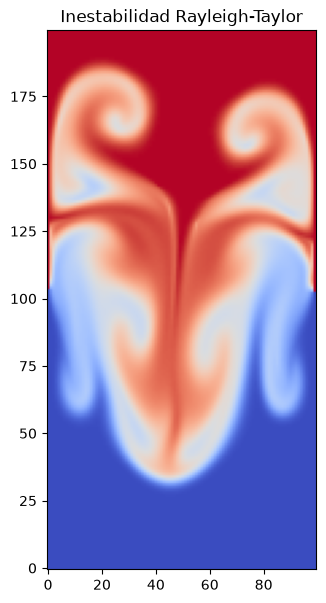

In [5]:
#Bucle Principal

for n in range(pasos):
    #Velocidades (u, v)
    dpsi_dy, dpsi_dx = np.gradient(psi, dy, dx)
    u =  dpsi_dy
    v = -dpsi_dx
    u[0, :] = u[-1, :] = 0.0
    v[:, 0] = v[:, -1] = 0.0

    #Advección Upwind
    u_pos, u_neg = np.maximum(u, 0), np.minimum(u, 0)
    v_pos, v_neg = np.maximum(v, 0), np.minimum(v, 0)

    #Advección de rho
    drho_dx_bwd = (rho[1:-1, 1:-1] - rho[1:-1, :-2]) / dx
    drho_dx_fwd = (rho[1:-1, 2:]   - rho[1:-1, 1:-1]) / dx
    drho_dy_bwd = (rho[1:-1, 1:-1] - rho[:-2, 1:-1]) / dy
    drho_dy_fwd = (rho[2:, 1:-1]   - rho[1:-1, 1:-1]) / dy

    advec_rho = (u_pos[1:-1, 1:-1] * drho_dx_bwd + u_neg[1:-1, 1:-1] * drho_dx_fwd +
                 v_pos[1:-1, 1:-1] * drho_dy_bwd + v_neg[1:-1, 1:-1] * drho_dy_fwd)

    #Advección de omega
    dom_dx_bwd = (omega[1:-1, 1:-1] - omega[1:-1, :-2]) / dx
    dom_dx_fwd = (omega[1:-1, 2:]   - omega[1:-1, 1:-1]) / dx
    dom_dy_bwd = (omega[1:-1, 1:-1] - omega[:-2, 1:-1]) / dy
    dom_dy_fwd = (omega[2:, 1:-1]   - omega[1:-1, 1:-1]) / dy

    advec_omega = (u_pos[1:-1, 1:-1] * dom_dx_bwd + u_neg[1:-1, 1:-1] * dom_dx_fwd +
                   v_pos[1:-1, 1:-1] * dom_dy_bwd + v_neg[1:-1, 1:-1] * dom_dy_fwd)

    rho[1:-1, 1:-1]   -= dt * advec_rho
    omega[1:-1, 1:-1] -= dt * advec_omega

    #Fuente de Gravedad
    _, drho_dx = np.gradient(rho, dy, dx)
    omega[1:-1, 1:-1] -= dt * (g / rho_0) * drho_dx[1:-1, 1:-1]

    #Poisson (Jacobi)
    for _ in range(100):
        psi[1:-1, 1:-1] = 0.25 * (
            psi[1:-1, 2:] + psi[1:-1, :-2] +
            psi[2:, 1:-1] + psi[:-2, 1:-1] +
            (dx**2) * omega[1:-1, 1:-1]
        )
fig, ax = plt.subplots(figsize=(4, 7))
ax.imshow(rho, cmap='coolwarm', origin='lower')
ax.set_title("Inestabilidad Rayleigh-Taylor")
plt.ioff()
plt.show()